# 02 · Ingeniería de variables y particionado

**Proyecto 3 · Minería de Datos (ISW-911) · Grupo Innova S.A.**  
**Responsable:** Jose Fabio Oconitrillo  
**Rama de trabajo:** `feature/fabio-preprocesamiento`  
**Criterio de la rúbrica:** 1. EDA y Preparación (10 %)

> Explicar y probar `src/preprocesamiento.py`: encoding, escalado, variables creadas y split reproducible sin data leakage.

_Regla: no borrar celdas de otros, documentar CADA decisión en Markdown (qué se hizo, por qué y qué alternativa se descartó)._

In [19]:
import sys
sys.path.append("..")  # para importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.datos import cargar_datos, dividir_train_test

sns.set_theme(style="whitegrid")
df = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(df)
print("Datos:", df.shape, "| Train:", X_train.shape, "| Test:", X_test.shape)

Datos: (110196, 27) | Train: (88156, 11) | Test: (22040, 11)


Se cargan **110 196 filas** (solo órdenes entregadas, igual que en el Lab 4) y se dividen en **88 156 de Train y 22 040 de Test**. Las 11 columnas de `X` son las que define `src/config.py`: 8 numéricas y 3 categóricas, todas conocidas **al momento de la compra**, que es cuando hay que cotizar el flete.

## 1. Variables creadas

Las dos variables nuevas se crean en `src/datos.py → crear_variables()`:

| Variable | Fórmula | Por qué tiene sentido para el flete |
|---|---|---|
| `volumen_cm3` | `largo_cm × alto_cm × ancho_cm` | Las transportistas no cobran solo por peso: cobran por **peso volumétrico** (el mayor entre el peso real y el volumen dividido por un factor). Una caja grande y liviana cuesta más de lo que su peso sugiere. Las tres medidas sueltas no capturan eso; su producto sí. |
| `mismo_estado` | `1` si `estado_cliente == estado_vendedor` | Es un indicador simple de **distancia**. El dataset no trae coordenadas, pero un envío dentro del mismo estado recorre menos kilómetros y suele pasar por menos centros de distribución. |

**¿Por qué crearlas antes de dividir no es fuga de información?** Porque cada valor se calcula **con la misma fila**, sin mirar a otras filas (no hay medias, medianas ni conteos). El resultado de una fila de Test sería idéntico si se calculara después de dividir.

**Alternativas descartadas:** calcular la distancia real entre códigos postales (requiere un dataset de geolocalización externo y no aporta tanto para el alcance del proyecto) y usar el par `estado_vendedor → estado_cliente` como categoría (≈600 combinaciones, demasiadas para One-Hot).

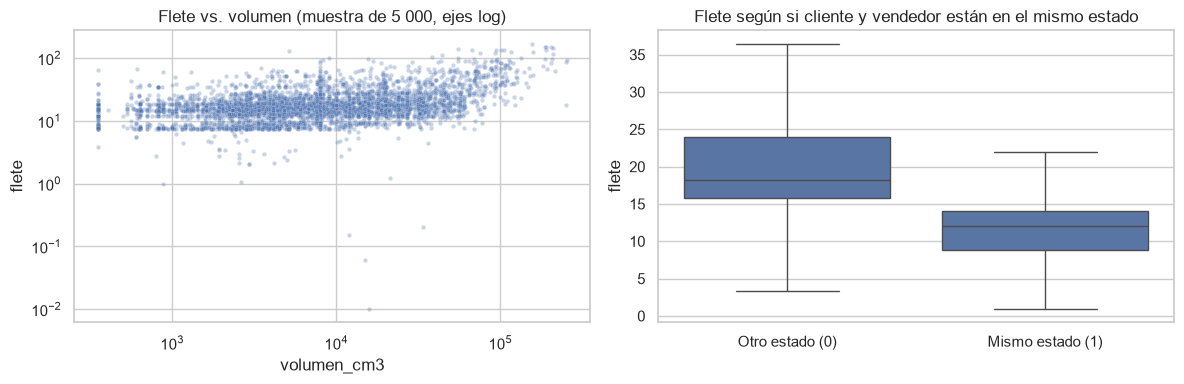

In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

muestra = df.sample(5000, random_state=config.RANDOM_STATE)
sns.scatterplot(data=muestra, x="volumen_cm3", y="flete", alpha=0.3, s=10, ax=ejes[0])
ejes[0].set(xscale="log", yscale="log", title="Flete vs. volumen (muestra de 5 000, ejes log)")

sns.boxplot(data=df, x="mismo_estado", y="flete", showfliers=False, ax=ejes[1])
ejes[1].set_xticks([0, 1], ["Otro estado (0)", "Mismo estado (1)"])
ejes[1].set(xlabel="",
            title="Flete según si cliente y vendedor están en el mismo estado")
plt.tight_layout()
config.FIGURAS.mkdir(parents=True, exist_ok=True)
plt.savefig(config.FIGURAS / "02_variables_creadas.png", dpi=120)
plt.show()

In [21]:
# Correlación de Spearman con el flete (por rangos: robusta a la asimetría y a los outliers)
corr = (df[["volumen_cm3", "peso_g", "largo_cm", "alto_cm", "ancho_cm", "precio", "mismo_estado", "flete"]]
        .corr(method="spearman")["flete"].drop("flete").sort_values(key=abs, ascending=False))
display(corr.round(3).to_frame("spearman_con_flete"))

display(df.groupby("mismo_estado")["flete"].agg(["count", "mean", "median"]).round(2))

,spearman_con_flete
mismo_estado,-0.607
peso_g,0.446
precio,0.434
volumen_cm3,0.368
largo_cm,0.283
alto_cm,0.282
ancho_cm,0.273


,count,mean,median
mismo_estado,,,
0,70333,23.63,18.24
1,39863,13.45,12.01


**Lectura:**
- `mismo_estado` es la variable con la correlación más fuerte con el flete (≈ −0.61): cuando cliente y vendedor están en el mismo estado, el flete mediano baja de **18.24 a 12.01** (≈34 % menos). Es la señal de distancia que buscábamos.
- `volumen_cm3` se relaciona positivamente con el flete (≈ 0.37) y lo hace de forma más estable que cada medida suelta, lo que respalda la idea del peso volumétrico. En la prueba rápida con Random Forest fue la variable **más importante (37 %)**.
- La relación es monótona pero **no lineal** (en ejes logarítmicos se ve como una nube creciente). Eso anticipa que los árboles van a rendir mejor que el modelo lineal (ver notebook 03).

## 2. Partición Train/Test

- **80 % Train / 20 % Test**, con `random_state=42` (`config.TEST_SIZE`, `config.RANDOM_STATE`). La semilla fija hace que **todos los integrantes** entrenen y evalúen sobre exactamente las mismas filas, así los modelos del notebook 03 y del 04 son comparables.
- **Se divide una sola vez, en `src/datos.py`**, y nadie vuelve a dividir en su notebook.
- **No se estratifica.** La estratificación (`stratify=y`) garantiza la misma proporción de cada **clase** en Train y Test; aplica a clasificación. El flete es **continuo** (miles de valores distintos), así que no hay clases que balancear. Con 110 000 filas, una partición aleatoria ya deja distribuciones prácticamente iguales, como se comprueba abajo.
- **Alternativa descartada:** partición temporal (entrenar con meses antiguos y probar con recientes). Sería más realista para producción, pero la rúbrica pide un Test aleatorio independiente y el equipo acordó usar el mismo split del Lab 4.

In [22]:
print(f"Train: {len(X_train):,} filas ({len(X_train)/len(df):.0%}) | Test: {len(X_test):,} filas ({len(X_test)/len(df):.0%})")
comparacion = pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2)
comparacion["diferencia_%"] = ((comparacion["test"] - comparacion["train"]) / comparacion["train"] * 100).round(1)
comparacion.loc["count", "diferencia_%"] = np.nan   # el tamaño ya se explica arriba (80/20)
comparacion

Train: 88,156 filas (80%) | Test: 22,040 filas (20%)


,train,test,diferencia_%
count,88156.00,22040.00,NaN
mean,19.97,19.84,-0.7
std,15.69,15.74,0.3
min,0.00,0.00,NaN
25%,13.08,12.92,-1.2
50%,16.28,16.16,-0.7
75%,21.15,21.03,-0.6
max,409.68,375.28,-8.4


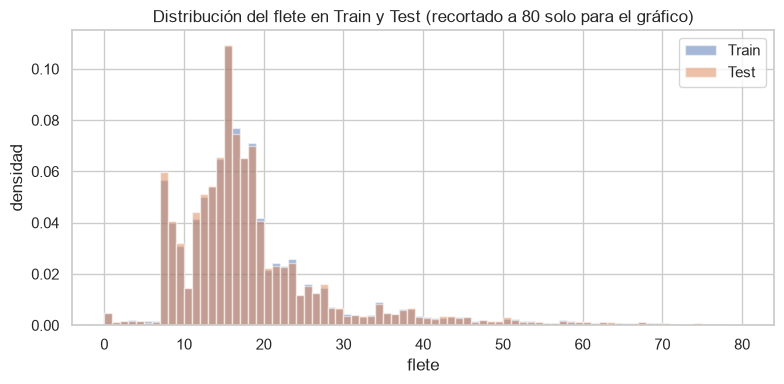

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 80, 81)
ax.hist(y_train, bins=bins, density=True, alpha=0.5, label="Train")
ax.hist(y_test, bins=bins, density=True, alpha=0.5, label="Test")
ax.set(title="Distribución del flete en Train y Test (recortado a 80 solo para el gráfico)",
       xlabel="flete", ylabel="densidad")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURAS / "02_split_train_test.png", dpi=120)
plt.show()

**Lectura:** media (19.97 vs 19.84), mediana (16.28 vs 16.16) y desviación estándar (15.69 vs 15.74) difieren en menos de 1 %, y los histogramas se superponen. El Test es representativo del Train sin necesidad de estratificar.

## 3. Preprocesador lineal vs. de árboles

`src/preprocesamiento.py` tiene dos funciones que devuelven un `ColumnTransformer`. Las dos comparten la imputación; cambian en el escalado y el encoding:

| | Preprocesador lineal (`crear_preprocesador_lineal`) | Preprocesador de árboles (`crear_preprocesador_arboles`) |
|---|---|---|
| **Numéricas** | Mediana + `StandardScaler` | Mediana (sin escalar) |
| **Categóricas** | `'sin_categoria'` + `OneHotEncoder` | `'sin_categoria'` + `OrdinalEncoder` |
| **Para** | Regresión lineal, Ridge, Lasso (notebook 03) | Árbol, Random Forest, Gradient Boosting (notebook 04) |

**Decisiones comunes:**
- **Imputar numéricas con la mediana** (decisión del Lab 4). Solo faltan 11 filas en las medidas del producto, pero las variables son muy asimétricas (pocos productos enormes), y la media quedaría arrastrada por esos extremos. *Descartado:* eliminar las filas (perderíamos filas también en Test, que debe quedar intacto) y la media.
- **Imputar `categoria_producto` con la constante `'sin_categoria'`** (1 269 nulos en Train, ≈1.4 %). Que un producto no tenga categoría puede ser información por sí misma; con la moda los mezclaríamos con la categoría más frecuente y perderíamos esa señal.
- **`handle_unknown`**: si en Test (o en producción) aparece una categoría que no estaba en Train, el One-Hot la deja en ceros (`ignore`) y el Ordinal le asigna −1, en vez de romperse.

**Por qué cada familia necesita la suya:**
- **Lineal:** Ridge y Lasso penalizan el tamaño de los coeficientes. Si `volumen_cm3` va de 0 a 300 000 y `mismo_estado` de 0 a 1, la penalización trataría distinto a cada variable solo por su unidad; el `StandardScaler` las deja a todas con media 0 y desviación 1. Además, un código ordinal (`SP=25`, `RJ=19`) le haría creer al modelo que "SP es mayor que RJ" y que el efecto crece en línea recta con el código: un orden falso. One-Hot crea una columna 0/1 por categoría y cada una recibe su propio coeficiente.
- **Árboles:** dividen por umbrales (`peso_g <= 2 000`), y un umbral funciona igual en gramos o estandarizado, así que escalar no cambia nada. Con el código ordinal el árbol puede agrupar categorías con varios cortes, y se evitan ~120 columnas One-Hot que harían el entrenamiento más lento y repartirían la importancia de una misma variable entre muchas columnas.

In [24]:
from src.preprocesamiento import crear_preprocesador_lineal, crear_preprocesador_arboles

# --- Lineal ---
prep = crear_preprocesador_lineal()
Xt = prep.fit_transform(X_train)   # aprende medianas, medias, desviaciones y categorías SOLO de Train
Xs = prep.transform(X_test)        # aplica lo aprendido; no vuelve a aprender
print("Lineal  -> Train:", Xt.shape, "| Test:", Xs.shape)

nombres_lin = prep.get_feature_names_out()
n_num = len(config.VARIABLES_NUMERICAS)
print(f"  {n_num} numéricas escaladas + {len(nombres_lin) - n_num} columnas One-Hot")
for col, cats in zip(config.VARIABLES_CATEGORICAS, prep.named_transformers_["cat"].named_steps["onehot"].categories_):
    print(f"    {col}: {len(cats)} categorías")

# --- Árboles ---
prep_arb = crear_preprocesador_arboles()
Xt_arb = prep_arb.fit_transform(X_train)
Xs_arb = prep_arb.transform(X_test)
print("Árboles -> Train:", Xt_arb.shape, "| Test:", Xs_arb.shape, "(una columna por variable)")

Lineal  -> Train: (88156, 129) | Test: (22040, 129)
  8 numéricas escaladas + 121 columnas One-Hot
    categoria_producto: 72 categorías
    estado_cliente: 27 categorías
    estado_vendedor: 22 categorías
Árboles -> Train: (88156, 11) | Test: (22040, 11) (una columna por variable)


In [25]:
# Las numéricas quedan con media ~0 y desv. ~1 en Train; en Test quedan CERCA, pero no exactas,
# porque se escalaron con la media y la desviación de Train (es lo correcto).
num_train = pd.DataFrame(Xt[:, :n_num].toarray() if hasattr(Xt, "toarray") else Xt[:, :n_num],
                         columns=config.VARIABLES_NUMERICAS)
num_test = pd.DataFrame(Xs[:, :n_num].toarray() if hasattr(Xs, "toarray") else Xs[:, :n_num],
                        columns=config.VARIABLES_NUMERICAS)
pd.DataFrame({"media_train": num_train.mean(), "desv_train": num_train.std(),
              "media_test": num_test.mean(), "desv_test": num_test.std()}).round(3)

,media_train,desv_train,media_test,desv_test
peso_g,-0.0,1.0,-0.004,0.997
largo_cm,-0.0,1.0,0.004,0.996
alto_cm,-0.0,1.0,-0.008,0.982
ancho_cm,-0.0,1.0,0.009,1.008
volumen_cm3,-0.0,1.0,0.002,0.999
precio,-0.0,1.0,0.007,1.044
numero_item,0.0,1.0,0.001,1.047
mismo_estado,0.0,1.0,0.013,1.004


In [26]:
# Vista rápida de cómo queda una fila con cada preprocesador
print("Fila original:")
display(X_train.head(1))
print("Preprocesador de árboles (categorías como códigos enteros):")
display(pd.DataFrame(Xt_arb[:1], columns=prep_arb.get_feature_names_out()))
fila_lin = pd.Series(Xt[0].toarray().ravel() if hasattr(Xt, "toarray") else Xt[0], index=nombres_lin)
print("Preprocesador lineal (solo las columnas distintas de 0):")
display(fila_lin[fila_lin != 0].round(3).to_frame("valor"))

Fila original:


,peso_g,largo_cm,alto_cm,ancho_cm,volumen_cm3,precio,numero_item,mismo_estado,categoria_producto,estado_cliente,estado_vendedor
85289,250.0,40.0,10.0,25.0,10000.0,19.9,1,1,watches_gifts,SP,SP


Preprocesador de árboles (categorías como códigos enteros):


,num__peso_g,num__largo_cm,num__alto_cm,num__ancho_cm,num__volumen_cm3,num__precio,num__numero_item,num__mismo_estado,cat__categoria_producto,cat__estado_cliente,cat__estado_vendedor
0,250.0,40.0,10.0,25.0,10000.0,19.9,1.0,1.0,71.0,25.0,21.0


Preprocesador lineal (solo las columnas distintas de 0):


,valor
num__peso_g,-0.492
num__largo_cm,0.612
num__alto_cm,-0.489
num__ancho_cm,0.174
num__volumen_cm3,-0.222
num__precio,-0.552
num__numero_item,-0.283
num__mismo_estado,1.332
cat__categoria_producto_watches_gifts,1.000
cat__estado_cliente_SP,1.000


**Lectura:** el preprocesador lineal pasa de 11 a **129 columnas** (8 numéricas + 121 One-Hot: 72 categorías de producto incluyendo `sin_categoria`, 27 estados de cliente y 22 de vendedor). El de árboles conserva **11 columnas**. Train y Test quedan con el mismo número de columnas porque el `transform` usa las categorías aprendidas en Train.

El One-Hot devuelve una matriz *dispersa* (casi todo ceros), que ahorra memoria y que Ridge/Lasso aceptan sin problema.

## 4. Por qué esto corrige el data leakage del Lab 4

**Qué es data leakage:** que información que el modelo no tendría en la vida real (del Test o del futuro) se cuele en el entrenamiento. El resultado es una métrica de Test optimista que no se repite en producción.

**Qué pasaba en el Lab 4:**
1. El `StandardScaler` se ajustó con **todo el conjunto** antes de dividir. La media y la desviación que usó incluían las filas de Test, así que el Test dejó de ser "datos nunca vistos": el preprocesamiento ya sabía algo de ellos.
2. El **flete se recortó** (outliers) también con todo el conjunto. Ahora que el flete es el target, recortarlo cambiaría justamente lo que queremos predecir, y en Test haría que los errores grandes desaparecieran artificialmente. En el Proyecto 3 **el target no se toca**.

**Cómo se corrige:**
- `src/datos.py` solo carga, filtra entregadas y crea variables fila por fila. **No imputa, no escala y no codifica.**
- Todo lo que aprende de los datos (medianas, medias, desviaciones, lista de categorías) está dentro del `ColumnTransformer`, y este va **dentro de un `Pipeline`** junto con el modelo: `Pipeline([("prep", crear_preprocesador_lineal()), ("modelo", Ridge())])`.
- Así, `fit` solo ve `X_train`. Y en `GridSearchCV` el Pipeline completo se reajusta **en cada fold**, por lo que tampoco hay fuga entre los folds de entrenamiento y el de validación (si escaláramos antes del `GridSearchCV`, la validación cruzada tendría la misma fuga en pequeño).
- Además se excluyen variables que se conocen **después** de la compra o que contienen el target: `valor_pago` (incluye el flete), fechas de entrega y reseña (`config.EXCLUIDAS_POR_FUGA`).

La celda siguiente lo demuestra: lo que aprende el Pipeline coincide con las estadísticas de **Train**, no con las del conjunto completo.

In [27]:
escalador = prep.named_transformers_["num"].named_steps["escalar"]
imputador = prep.named_transformers_["num"].named_steps["imputar"]
X_todo = df[config.VARIABLES_NUMERICAS]

demo = pd.DataFrame({
    "media_aprendida_pipeline": escalador.mean_,
    "media_solo_train": X_train[config.VARIABLES_NUMERICAS].fillna(X_train[config.VARIABLES_NUMERICAS].median()).mean().values,
    "media_todo_el_conjunto (Lab 4)": X_todo.fillna(X_todo.median()).mean().values,
    "mediana_aprendida_pipeline": imputador.statistics_,
    "mediana_solo_train": X_train[config.VARIABLES_NUMERICAS].median().values,
}, index=config.VARIABLES_NUMERICAS)
display(demo.round(3))

ok = (np.allclose(demo["media_aprendida_pipeline"], demo["media_solo_train"])
      and np.allclose(demo["mediana_aprendida_pipeline"], demo["mediana_solo_train"]))
print("¿El Pipeline aprendió solo de Train?", ok)

,media_aprendida_pipeline,media_solo_train,media_todo_el_conjunto (Lab 4),mediana_aprendida_pipeline,mediana_solo_train
peso_g,2092.450,2092.450,2089.392,700.00,700.00
largo_cm,30.130,30.130,30.141,25.00,25.00
alto_cm,16.576,16.576,16.555,13.00,13.00
ancho_cm,22.964,22.964,22.986,20.00,20.00
volumen_cm3,15161.031,15161.031,15172.219,6426.00,6426.00
precio,119.728,119.728,119.976,74.99,74.99
numero_item,1.198,1.198,1.198,1.00,1.00
mismo_estado,0.360,0.360,0.362,0.00,0.00


¿El Pipeline aprendió solo de Train? True


**Lectura:** las medias y medianas aprendidas por el Pipeline son **idénticas a las de Train** y distintas de las del conjunto completo que usó el Lab 4. Las diferencias son pequeñas con 110 000 filas, pero el principio es el que evalúa la rúbrica: el Test se transforma con parámetros que nunca lo vieron, igual que pasaría con un pedido nuevo en producción.

## Conclusiones

1. **Variables creadas:** `volumen_cm3` (peso volumétrico) y `mismo_estado` (distancia) tienen justificación de negocio y confirman su valor en los datos: `mismo_estado` es la variable más correlacionada con el flete (≈ −0.61) y `volumen_cm3` fue la más importante del Random Forest en la prueba rápida. Se crean antes de dividir sin fuga porque solo usan la propia fila.
2. **Partición:** 88 156 Train / 22 040 Test con semilla 42, compartida por todo el equipo. No se estratifica porque es regresión, y las distribuciones del flete en Train y Test difieren en menos de 1 %.
3. **Dos preprocesadores:** el lineal (mediana + escalado + One-Hot, 129 columnas) porque Ridge/Lasso son sensibles a la escala y no deben leer un orden falso en las categorías; el de árboles (mediana + Ordinal, 11 columnas) porque los árboles no necesitan escalado y One-Hot los volvería lentos.
4. **Sin data leakage:** todo lo que aprende de los datos va dentro de un `Pipeline` que se ajusta solo con Train (y se reajusta en cada fold de la validación cruzada). Se corrige el error del Lab 4 (escalado con todo el conjunto y recorte del flete) y se excluyen variables posteriores a la compra.

**Siguiente paso:** el notebook 03 usa `crear_preprocesador_lineal()` para el Modelo 1 (Ridge/Lasso) y el notebook 04 usa `crear_preprocesador_arboles()`.